In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../src")

import pandas as pd
from sklearn.model_selection import cross_val_predict
from features import FEATURES, build_features
from train import build_model

raw = pd.read_pickle("../data/raw/shots.pkl")
df = build_features(raw)

df["xg"] = cross_val_predict(
    build_model(), df[FEATURES], df["is_goal"], cv=5, method="predict_proba"
)[:, 1]

print(f"xG total : {df['xg'].sum():.1f}  |  buts réels : {df['is_goal'].sum()}")

xG total : 507.6  |  buts réels : 507


In [2]:
player_name = df[df["player"].str.contains("Mbapp", na=False)]["player"].iloc[0]
shots = df[df["player"] == player_name]

print(f"{player_name} | {len(shots)} tirs | {shots['is_goal'].sum()} buts | {shots['xg'].sum():.1f} xG")

Kylian Mbappé Lottin | 74 tirs | 10 buts | 7.7 xG


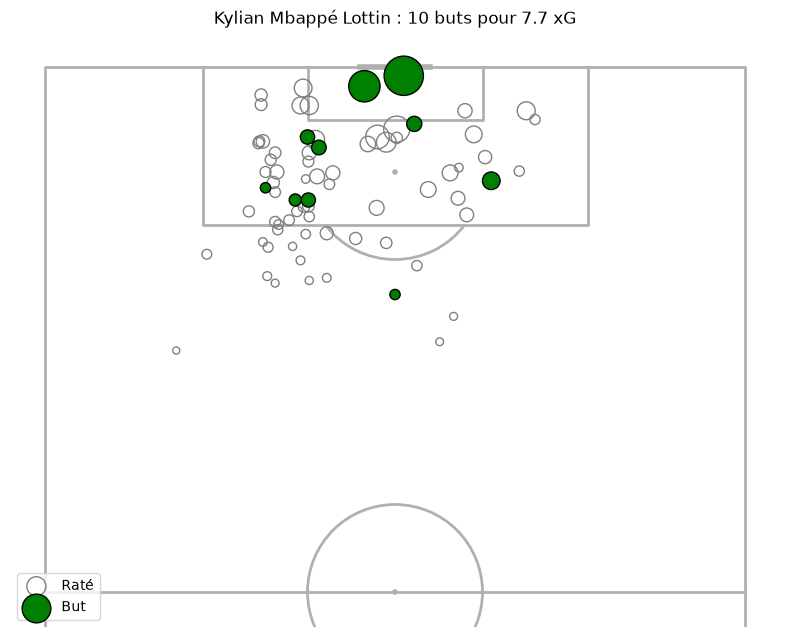

In [3]:
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

pitch = VerticalPitch(pitch_type="statsbomb", half=True)
fig, ax = pitch.draw(figsize=(8, 7))

goals = shots[shots["is_goal"] == 1]
misses = shots[shots["is_goal"] == 0]

pitch.scatter(misses["x"], misses["y"], s=misses["xg"] * 800 + 20, ax=ax,
              facecolors="none", edgecolors="grey", label="Raté")
pitch.scatter(goals["x"], goals["y"], s=goals["xg"] * 800 + 20, ax=ax,
              color="green", edgecolors="black", label="But")

ax.legend(loc="lower left")
ax.set_title(f"{player_name} : {shots['is_goal'].sum()} buts pour {shots['xg'].sum():.1f} xG")
plt.show()

In [4]:
finishers = df.groupby("player").agg(
    shots=("is_goal", "size"),
    goals=("is_goal", "sum"),
    xg=("xg", "sum"),
)
finishers["goals_minus_xg"] = finishers["goals"] - finishers["xg"]
finishers = finishers[finishers["shots"] >= 20]

finishers.sort_values("goals_minus_xg", ascending=False).head(10).round(2)

,shots,goals,xg,goals_minus_xg
player,,,,
Xherdan Shaqiri,29,6,1.71,4.29
Harry Kane,53,10,6.95,3.05
Patrik Schick,22,5,2.55,2.45
Kylian Mbappé Lottin,74,10,7.68,2.32
Emil Peter Forsberg,28,4,1.70,2.30
Ivan Perišić,51,6,3.74,2.26
Luka Modrić,21,3,1.10,1.90
Álvaro Borja Morata Martín,39,7,5.11,1.89
Jamal Musiala,21,3,1.76,1.24
